# 02 · Descriptive analysis (Q1 and Q3)

**DSCI 510 project: Anticipating Attacks on Software Flaws**

This notebook answers the project's two descriptive questions from the analysis table that
`01_acquire_data.ipynb` built. Neither depends on any model.

| Question | What is measured |
|:--|:--|
| **Q1.** How rare is exploitation, and where is it concentrated? | Exploitation rates by period and year, by severity at publication, by CVSS component, by weakness class and by publisher; how concentrated exploitation is among publishers; and what severity-based triage costs in effort and precision |
| **Q3.** How soon after publication are vulnerabilities listed as exploited, and has that interval changed? | For CVEs published in 2022, 2023 and 2024: the share listed on or before the publication day, and the delay to listing, with its change over time |

**Inputs:** `data/processed/analysis_table.parquet` and `analysis_table_columns.csv`, and the
acquisition log to check them against.

**Outputs:** tables in `results/` (CSV) and figures in `figures/` (PNG), ready for the report and
the presentation.

**Runtime:** under a minute, plus one small request to the NVD for publishers' names (cached after
the first run).

**Conventions used throughout:**

- **Exploited** means listed in KEV within 365 calendar days of publication (`label_365`).
- **The modelling period** runs from November 3, 2021 to December 31, 2024. Earlier CVEs have no fair
  label (KEV did not exist yet) and are left out of every rate.
- **Uncertainty:** every rate comes with a 95% interval, and counts are always shown beside rates,
  because some groups are small.
- **Listings before publication:** as the proposal committed, key results are given with and without
  CVEs that KEV listed before their record was published.

**A rule about the test year:** these tables include 2024, the year the model will be tested on.
They describe the data and go into the report, but no modelling decision in `03_model.ipynb` may be
based on a 2024 figure. Design choices there use the training and validation periods only, which is
why most tables show each period separately.

---

## Stage A · Setup

### Step 1 · Libraries and settings

**What we are doing:** importing the libraries and fixing every setting in one place: folders,
periods, the random seed, and the thresholds used to decide which groups are large enough to rank.

**Why:** a setting that appears once, at the top, can be checked and changed without searching the
code. The random seed makes the bootstrap intervals identical on every run.

In [1]:
import json, re, time
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter

VERSIONS = {"pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__}
print(" | ".join(f"{name} {version}" for name, version in VERSIONS.items()))

pandas 3.0.3 | numpy 2.4.6 | matplotlib 3.11.0


**The settings:** the next cell fixes the folders, the periods and the analysis constants.

In [2]:
# ---- Folders ----
PROCESSED = Path("data") / "processed"
RAW       = Path("data") / "raw"
RESULTS   = Path("results")                   # CSV tables for the report
FIGURES   = Path("figures")                   # PNG figures for the report and slides
LOGS      = Path("logs")
for folder in (RESULTS, FIGURES, LOGS):
    folder.mkdir(parents=True, exist_ok=True)

# ---- Periods (fixed in 01_acquire_data.ipynb) ----
PERIODS = ["train", "validate", "test"]       # the modelling period, in time order
PERIOD_NAMES = {"train": "Nov 2021–2022", "validate": "2023", "test": "2024"}
COHORTS = ["2021 (Nov–Dec)", "2022", "2023", "2024"]   # publication years within the modelling period
LABEL = "label_365"                           # listed in KEV within 365 calendar days
LABEL_DAYS = 365                              # the label's window, in calendar days

# ---- Analysis constants ----
SEED = 510                                    # fixed, so bootstrap intervals repeat exactly
N_BOOT = 1000                                 # bootstrap resamples, as stated in the proposal
Z95 = 1.959964                                # normal quantile for a 95% interval
MIN_CVES = 200                                # smallest group whose rate is ranked
TOP_N = 12                                    # rows shown in the "top" tables and figures

print(f"settings ready | periods {PERIODS} | {N_BOOT} bootstrap resamples, seed {SEED}")

settings ready | periods ['train', 'validate', 'test'] | 1000 bootstrap resamples, seed 510


**Reading the result:** one line confirming the settings. `results/` and `figures/` are created
beside the notebook if they don't exist.

### Step 2 · Recording checks and saving outputs

**What we are doing:** defining the small functions the rest of the notebook uses to record checks
(`PASS`, `WARN` or `FAIL`, as in the earlier notebooks) and to save tables and figures.

**Why:** every check and every file is kept in one record, which the summary at the end lists and
saves as `logs/descriptive_log.json`.

In [3]:
def now_iso():
    "Current local time with its UTC offset."
    return dt.datetime.now().astimezone().isoformat(timespec="seconds")

RUN = {"started": now_iso(), "checks": {}, "files": [], "versions": VERSIONS}

def check(name, ok, **details):
    "Record one check and print its verdict. ok=True is PASS, False is FAIL, None is WARN."
    verdict = "WARN" if ok is None else ("PASS" if ok else "FAIL")
    RUN["checks"][name] = {"verdict": verdict, **details}
    print(f"{verdict}  {name}" + (f"  |  {details}" if details else ""))

def show_conditions(conditions):
    "Print a {description: passed} checklist; return the descriptions that failed."
    for description, passed in conditions.items():
        print(f"  {'ok ' if passed else 'NO '} {description}")
    return [description for description, passed in conditions.items() if not passed]

def save_table(df, name, index=True):
    "Save a result table as results/<name>.csv and remember it for the summary."
    path = RESULTS / f"{name}.csv"
    df.to_csv(path, index=index)
    RUN["files"].append(str(path))
    return path

The cell above defines the record. The next one sets the look of every figure.

**The chart style:** thin bars, hairline grids, no top or right frame, and three colours (blue,
orange and aqua) for the three periods. These colours were checked with a colour-vision validator:
they stay distinguishable for the common forms of colour blindness. The aqua is light on a white
background, so every figure also has a legend and its numbers are saved as a table. A single-series
chart uses the blue alone.

In [4]:
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#898781"          # primary, secondary, muted text
COLORS = {"train": "#2a78d6", "validate": "#eb6834", "test": "#1baf7a"}   # validated, in this order
COHORT_COLORS = {"2022": COLORS["train"], "2023": COLORS["validate"], "2024": COLORS["test"]}
ACCENT, CONTEXT = "#2a78d6", "#c3c2b7"                        # one highlighted series; the rest

def pick_font(candidates=("Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans")):
    "The first installed font from the list (checked quietly, so matplotlib prints no warnings)."
    for name in candidates:
        try:
            font_manager.findfont(name, fallback_to_default=False)
            return name
        except ValueError:
            continue
    return "sans-serif"

plt.rcParams.update({
    "font.family": pick_font(), "font.size": 9.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_3, "ytick.color": INK_3, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "text.color": INK,
})

def save_figure(fig, name, note=None):
    "Add an optional note just below everything drawn (whatever the figure size), save figures/<name>.png, show it."
    if note:
        fig.canvas.draw()                                         # lay out first, so the bounding box is final
        box = fig.get_tightbbox(fig.canvas.get_renderer())       # in inches
        fig.text(box.x0 / fig.get_figwidth(), (box.y0 - 0.08) / fig.get_figheight(), note,
                 ha="left", va="top", fontsize=8, color=INK_3)
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    RUN["files"].append(str(path))
    plt.show()
    plt.close(fig)

print("chart style ready | font:", plt.rcParams["font.family"][0] if isinstance(plt.rcParams["font.family"], list) else plt.rcParams["font.family"])

chart style ready | font: Segoe UI


**Reading the result:** the name of the font in use. On Windows it is normally Segoe UI; any of the
fallbacks is fine.

### Step 3 · Statistical helpers

**What we are doing:** defining the two tools used for uncertainty, both written with NumPy.

- **`wilson_interval`** gives a 95% interval for a rate such as "7 of 378". It is the standard interval
  for proportions and, unlike the simple ±1.96 standard errors, stays sensible for small counts and
  for rates near zero, which is exactly our situation.
- **`bootstrap_ci`** and **`bootstrap_difference`** give intervals for statistics without a simple
  formula, such as a median delay or the change in a median between two years. They resample the data
  1,000 times with NumPy's random generator and take the 2.5th and 97.5th percentiles, as the
  proposal set out.

**Why:** with 128 to 149 exploited CVEs per period, many differences between groups are within
chance. The intervals keep the report from reading meaning into noise.

In [5]:
def wilson_interval(k, n, z=Z95):
    "95% Wilson score interval for k successes out of n (vectorised; works on arrays)."
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):      # n = 0 gives NaN, by design
        p = k / n
        denominator = 1 + z**2 / n
        centre = (p + z**2 / (2 * n)) / denominator
        half_width = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
    return np.clip(centre - half_width, 0, 1), np.clip(centre + half_width, 0, 1)

def bootstrap_ci(values, stat=np.median, n_boot=N_BOOT, seed=SEED):
    "95% percentile bootstrap interval for stat(values). `stat` must accept axis=1."
    values = np.asarray(values, dtype=float)
    if values.size == 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(n_boot, values.size), replace=True)
    return tuple(np.percentile(stat(samples, axis=1), [2.5, 97.5]))

def bootstrap_difference(a, b, stat=np.median, n_boot=N_BOOT, seed=SEED):
    "stat(b) - stat(a), with a 95% interval from resampling each group independently."
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    rng = np.random.default_rng(seed)
    diffs = (stat(rng.choice(b, size=(n_boot, b.size)), axis=1)
             - stat(rng.choice(a, size=(n_boot, a.size)), axis=1))
    low, high = np.percentile(diffs, [2.5, 97.5])
    return stat(b) - stat(a), low, high

**What we are doing next:** testing both tools on cases with known answers before using them.

**Why:** the Wilson interval for 5 out of 100 is a textbook value (2.15% to 11.2%), and an interval
for 0 out of 10 must start at zero. A bootstrap of a constant must return that constant, and
the same seed must give the same answer twice.

In [6]:
low, high = wilson_interval([5, 0, 50], [100, 10, 50])
ci_constant = bootstrap_ci(np.full(40, 7.0))
ci_a, ci_b = bootstrap_ci(np.arange(100)), bootstrap_ci(np.arange(100))
estimate, d_low, d_high = bootstrap_difference(np.zeros(30), np.ones(30))
failed = show_conditions({
    "Wilson 5/100 = 2.15% to 11.2%": np.allclose([low[0], high[0]], [0.0215, 0.1118], atol=5e-4),
    "Wilson 0/10 starts at 0 and ends near 27.8%": low[1] < 1e-12 and abs(high[1] - 0.2775) < 5e-4,
    "Wilson 50/50 ends at 100%": high[2] > 1 - 1e-12,
    "bootstrap of a constant returns the constant": ci_constant == (7.0, 7.0),
    "the same seed gives the same interval": ci_a == ci_b,
    "the interval contains the sample median": ci_a[0] <= np.median(np.arange(100)) <= ci_a[1],
    "a difference of exactly 1 is estimated as 1": (estimate, d_low, d_high) == (1.0, 1.0, 1.0),
})
check("A1-statistics-selftest", not failed, tests=7, failed=failed)

  ok  Wilson 5/100 = 2.15% to 11.2%
  ok  Wilson 0/10 starts at 0 and ends near 27.8%
  ok  Wilson 50/50 ends at 100%
  ok  bootstrap of a constant returns the constant
  ok  the same seed gives the same interval
  ok  the interval contains the sample median
  ok  a difference of exactly 1 is estimated as 1
PASS  A1-statistics-selftest  |  {'tests': 7, 'failed': []}


**Reading the result:** seven `ok` lines and `PASS`.

---

## Stage B · The data

### Step 4 · Load the analysis table and check it against the acquisition run

**What we are doing:** loading the analysis table and its column dictionary, and comparing the row
count and the exploited counts with what `01_acquire_data.ipynb` recorded in its log.

**Why:** the descriptive results are only as good as the table they come from. Matching the
acquisition log confirms that this is the complete, checked table, not an older or partial copy.

In [7]:
def load_acquisition_reference(path=LOGS / "acquisition_log.json"):
    "Rows and exploited counts per split recorded by 01_acquire_data.ipynb, or None if unavailable."
    try:
        log = json.loads(path.read_text(encoding="utf-8"))
        d2 = log["checks"]["D2-analysis-table"]
        return {"rows": d2["rows"], "exploited": d2["exploited"], "started": log["started"]}
    except (FileNotFoundError, KeyError, json.JSONDecodeError) as exc:
        print(f"no usable acquisition log ({exc!r}): the comparison below will be WARN")
        return None

table = pd.read_parquet(PROCESSED / "analysis_table.parquet")
columns = pd.read_csv(PROCESSED / "analysis_table_columns.csv")
reference = load_acquisition_reference()

needed = {"cve_id", "published", "pub_year", "split", "cna", "cvss_score", "cvss_vector",
          "cvss_version", "cwe_primary", LABEL, "days_to_kev", "kev_before_publication", "in_kev"}
exploited = table.groupby("split")[LABEL].sum().astype(int).to_dict()
failed = show_conditions({                                   # integrity: must hold in any case
    "every needed column is present": needed <= set(table.columns),
    "one row per CVE": not table["cve_id"].duplicated().any(),
    "the label has no missing values": int(table[LABEL].isna().sum()) == 0,
})
if reference:                                                # agreement with the acquisition run
    failed += show_conditions({
        "rows match the acquisition run": len(table) == reference["rows"],
        "exploited per split match the acquisition run": exploited == reference["exploited"],
    })
ok = False if failed else (True if reference else None)      # no reference to compare with: WARN
check("B1-table-loaded", ok, rows=len(table), exploited=exploited, failed=failed)

  ok  every needed column is present
  ok  one row per CVE
  ok  the label has no missing values
  ok  rows match the acquisition run
  ok  exploited per split match the acquisition run
PASS  B1-table-loaded  |  {'rows': 187219, 'exploited': {'pre-KEV': 159, 'test': 149, 'train': 128, 'validate': 145}, 'failed': []}


**Reading the result:** 187,219 rows, and exploited counts of 159 (pre-KEV), 128 (train), 145
(validate) and 149 (test), exactly as in the acquisition log. A `FAIL` means the table on disk is
not the one the acquisition run produced; re-run `01_acquire_data.ipynb` before going further.

### Step 5 · Readable publisher names

**What we are doing:** turning publisher identifiers such as `secure@microsoft.com` or a UUID into
names. The NVD publishes this mapping through its Source API: each source has a `name` and a list of
`sourceIdentifiers`, as the official schema documents. The list is downloaded once and cached in
`data/raw/nvd_sources.json`.

**Why:** a table of e-mail addresses and UUIDs is hard to read, and some organisations publish under
more than one identifier, so grouping by name keeps one publisher in one row. If the request fails,
the notebook falls back to the identifier itself (the part after the `@`, or the start of a UUID)
and marks the check `WARN`, so the analysis never depends on the network.

In [8]:
SOURCE_URL = "https://services.nvd.nist.gov/rest/json/source/2.0"
SOURCES_CACHE = RAW / "nvd_sources.json"

def fetch_sources(cache=SOURCES_CACHE, pause=6.0):
    "Every NVD source (organisation), from the cache if present, otherwise from the Source API."
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8")), "cache"
    sources, start = [], 0
    while True:
        resp = requests.get(SOURCE_URL, params={"startIndex": start}, timeout=60,
                            headers={"User-Agent": "DSCI510-course-project/1.0 (academic research)"})
        resp.raise_for_status()
        page = resp.json()
        batch = page.get("sources", [])
        sources += batch
        start += len(batch)
        if not batch or start >= page.get("totalResults", 0):
            break
        time.sleep(pause)                                  # NIST's pacing request
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(sources), encoding="utf-8")
    return sources, "NVD Source API"

def fallback_name(identifier):
    "A readable stand-in: the domain of an e-mail identifier, or the start of a UUID."
    if not isinstance(identifier, str) or not identifier:
        return "(unknown)"
    return identifier.split("@", 1)[1] if "@" in identifier else identifier[:8] + "…"

The cell above defines the download (with its cache) and the fallback. The next cell runs them and
adds a `publisher` column.

In [9]:
try:
    sources, origin = fetch_sources()
except (requests.RequestException, ValueError) as exc:        # no network, or an unexpected reply
    sources, origin = [], f"unavailable ({type(exc).__name__})"

NAMES = {identifier: s["name"].strip() for s in sources if s.get("name")
         for identifier in s.get("sourceIdentifiers", [])}
table["publisher"] = table["cna"].map(NAMES).fillna(table["cna"].map(fallback_name))

resolved = float(table["cna"].isin(list(NAMES)).mean())
print(f"{len(sources):,} sources from {origin}; {len(NAMES):,} identifiers mapped; "
      f"{resolved:.1%} of CVEs have a named publisher")
print(f"{table['cna'].nunique():,} identifiers -> {table['publisher'].nunique():,} publishers")
check("B2-publisher-names", True if resolved >= 0.95 else None, source=origin, resolved=round(resolved, 4))

528 sources from cache; 831 identifiers mapped; 100.0% of CVEs have a named publisher
359 identifiers -> 359 publishers
PASS  B2-publisher-names  |  {'source': 'cache', 'resolved': 1.0}


**Reading the result:** normally a few hundred sources and almost every CVE matched to a name
(`PASS`). If the NVD could not be reached, the check is `WARN` and the tables use domains instead of
names: the numbers are unaffected, though an organisation that used two identifiers would appear twice.

### Step 6 · The columns the analysis groups by

**What we are doing:** keeping the modelling period and adding the columns the tables group by:

| Column | Built from | Values |
|:--|:--|:--|
| `period` | `split` | train, validate, test |
| `cohort` | publication year | 2021 (Nov–Dec), 2022, 2023, 2024 |
| `severity` | the publisher's CVSS score | Critical (9.0+), High (7.0–8.9), Medium (4.0–6.9), Low or none (below 4.0), No publisher score |
| `weakness` | the publisher's first CWE, with a short name | for example "CWE-787 Out-of-bounds write", or "No publisher CWE" |
| `attack_vector`, `privileges`, `user_interaction` | the publisher's CVSS vector (versions 3.x and 4.0) | for example Network / Local; No privileges / Low / High |
| `label_after_pub` | `label_365` and `kev_before_publication` | exploited, but not listed before publication |

**Why:** missing values become named groups ("No publisher score", "No publisher CWE") instead of
being dropped, because, as the validation showed, many exploited CVEs had no publisher score at all.
Severity bands are taken from the score with the standard CVSS thresholds, so every CVSS version is
banded the same way.

In [10]:
CWE_NAMES = {   # short forms of MITRE's CWE names, for the weaknesses that recur most
    "CWE-20": "Improper input validation", "CWE-22": "Path traversal", "CWE-59": "Link following",
    "CWE-73": "External control of file name", "CWE-74": "Injection", "CWE-77": "Command injection",
    "CWE-78": "OS command injection", "CWE-79": "Cross-site scripting", "CWE-89": "SQL injection",
    "CWE-94": "Code injection", "CWE-119": "Memory buffer bounds", "CWE-120": "Classic buffer overflow",
    "CWE-121": "Stack-based buffer overflow", "CWE-122": "Heap-based buffer overflow",
    "CWE-125": "Out-of-bounds read", "CWE-190": "Integer overflow", "CWE-200": "Information exposure",
    "CWE-269": "Improper privilege management", "CWE-276": "Incorrect default permissions",
    "CWE-284": "Improper access control", "CWE-287": "Improper authentication",
    "CWE-288": "Authentication bypass (alternate path)", "CWE-306": "Missing authentication",
    "CWE-352": "Cross-site request forgery", "CWE-362": "Race condition",
    "CWE-400": "Uncontrolled resource consumption", "CWE-401": "Memory leak",
    "CWE-416": "Use after free", "CWE-427": "Uncontrolled search path",
    "CWE-434": "Unrestricted file upload", "CWE-476": "NULL pointer dereference",
    "CWE-502": "Deserialization of untrusted data", "CWE-601": "Open redirect",
    "CWE-611": "XML external entity", "CWE-639": "Authorization bypass (user-controlled key)",
    "CWE-668": "Exposure to wrong sphere", "CWE-693": "Protection mechanism failure",
    "CWE-732": "Incorrect permission assignment", "CWE-770": "Allocation without limits",
    "CWE-787": "Out-of-bounds write", "CWE-798": "Hard-coded credentials", "CWE-843": "Type confusion",
    "CWE-862": "Missing authorization", "CWE-863": "Incorrect authorization",
    "CWE-917": "Expression language injection", "CWE-918": "Server-side request forgery",
    "CWE-1321": "Prototype pollution",
}

SEVERITIES = ["Critical", "High", "Medium", "Low or none", "No publisher score"]

def severity_band(score):
    "CVSS bands from the score itself, so every CVSS version is banded the same way."
    bands = np.select([score.ge(9), score.ge(7), score.ge(4), score.notna()],
                      ["Critical", "High", "Medium", "Low or none"], default="No publisher score")
    return pd.Categorical(bands, categories=SEVERITIES, ordered=True)

The cell above holds the CWE short names and the severity banding. The next cell parses the CVSS
vector.

**Parsing the vector:** a CVSS 3.x vector looks like `CVSS:3.1/AV:N/AC:L/PR:N/UI:N/...` and a 4.0
vector like `CVSS:4.0/AV:N/AC:L/AT:N/PR:N/UI:N/...`. Both name the attack vector (`AV`), the privileges
required (`PR`) and user interaction (`UI`) with the same codes, except that 4.0 splits "required"
into passive (`P`) and active (`A`) interaction. Version 2 vectors use different components and
are left unparsed. The "none" values are named **No privileges** and **Not
required** rather than "None": pandas treats the word "None" in a CSV file as a missing value, so the
saved tables would otherwise lose those labels when read back. A short self-test checks the parser on hand-written vectors.

In [11]:
AV_NAMES = {"N": "Network", "A": "Adjacent", "L": "Local", "P": "Physical"}
PR_NAMES = {"N": "No privileges", "L": "Low", "H": "High"}   # not "None": pandas reads that word back as missing
UI_NAMES = {"N": "Not required", "R": "Required", "P": "Required", "A": "Required"}   # 4.0: passive/active

def cvss_components(vectors):
    "Attack vector, privileges required and user interaction from CVSS 3.x/4.0 vectors."
    v = vectors.where(vectors.str.startswith("CVSS:3", na=False) | vectors.str.startswith("CVSS:4", na=False))
    return pd.DataFrame({
        "attack_vector": v.str.extract(r"/AV:([NALP])", expand=False).map(AV_NAMES),
        "privileges": v.str.extract(r"/PR:([NLH])", expand=False).map(PR_NAMES),
        "user_interaction": v.str.extract(r"/UI:([NRPA])", expand=False).map(UI_NAMES),
    }, index=vectors.index)

_parsed = cvss_components(pd.Series(["CVSS:3.1/AV:N/AC:L/PR:N/UI:R/S:U/C:H/I:H/A:H",
                                     "CVSS:4.0/AV:L/AC:L/AT:N/PR:H/UI:P/VC:H/VI:H/VA:H/SC:N/SI:N/SA:N",
                                     "AV:N/AC:L/Au:N/C:P/I:P/A:P", None]))
failed = show_conditions({
    "a 3.1 vector: Network, No privileges, Required":
        _parsed.iloc[0].tolist() == ["Network", "No privileges", "Required"],
    "a 4.0 vector: Local, High, Required (passive)": _parsed.iloc[1].tolist() == ["Local", "High", "Required"],
    "a version 2 vector is left unparsed": _parsed.iloc[2].isna().all(),
    "a missing vector stays missing": _parsed.iloc[3].isna().all(),
})
check("B3-cvss-parser-selftest", not failed, tests=4, failed=failed)

  ok  a 3.1 vector: Network, No privileges, Required
  ok  a 4.0 vector: Local, High, Required (passive)
  ok  a version 2 vector is left unparsed
  ok  a missing vector stays missing
PASS  B3-cvss-parser-selftest  |  {'tests': 4, 'failed': []}


**Reading the result:** four `ok` lines and `PASS`.

**Building the modelling-period table:** the next cell keeps the modelling period and adds every
derived column at once.

In [12]:
def modelling_table(table):
    "The modelling period (Nov 3, 2021 - Dec 31, 2024) with every column the analysis groups by."
    m = table[table["split"].isin(PERIODS)].copy()
    m["period"] = pd.Categorical(m["split"], categories=PERIODS, ordered=True)
    years = m["pub_year"].astype(int)
    m["cohort"] = pd.Categorical(np.where(years == 2021, COHORTS[0], years.astype(str)),
                                 categories=COHORTS, ordered=True)
    m["severity"] = severity_band(m["cvss_score"])
    m["weakness"] = m["cwe_primary"].map(lambda c: f"{c} {CWE_NAMES[c]}" if c in CWE_NAMES else c)
    m["weakness"] = m["weakness"].fillna("No publisher CWE")
    m = m.join(cvss_components(m["cvss_vector"]))
    m["label_after_pub"] = m[LABEL] & ~m["kev_before_publication"]
    return m

model = modelling_table(table)
failed = show_conditions({
    "the modelling period has every train, validate and test row": len(model) == int(table["split"].isin(PERIODS).sum()),
    "every row has a period, a cohort and a severity band": not model[["period", "cohort", "severity"]].isna().any().any(),
    "no score is lost: banded scores = scores present": int((model["severity"] != "No publisher score").sum()) == int(model["cvss_score"].notna().sum()),
    "label_after_pub never exceeds label_365": not (model["label_after_pub"] & ~model[LABEL]).any(),
})
print(f"{len(model):,} CVEs in the modelling period, {int(model[LABEL].sum())} exploited "
      f"({int(model['kev_before_publication'].sum())} of them listed before publication)")
print(f"CVSS components parsed for {model['attack_vector'].notna().mean():.1%} of CVEs "
      f"(those with a publisher CVSS 3.x or 4.0 vector)")
check("B4-derived-columns", not failed, rows=len(model), failed=failed)

  ok  the modelling period has every train, validate and test row
  ok  every row has a period, a cohort and a severity band
  ok  no score is lost: banded scores = scores present
  ok  label_after_pub never exceeds label_365
97,137 CVEs in the modelling period, 422 exploited (55 of them listed before publication)
CVSS components parsed for 59.0% of CVEs (those with a publisher CVSS 3.x or 4.0 vector)
PASS  B4-derived-columns  |  {'rows': 97137, 'failed': []}


**Reading the result:** 97,137 CVEs in the modelling period, 422 of them exploited (55 listed before
their record was published), and the share of CVEs whose publisher supplied a parseable vector. Every
later table starts from this `model` table.

---

## Stage C · Q1: How rare is exploitation, and where is it concentrated?

### Step 7 · Tools for rate tables and charts

**What we are doing:** defining the functions every Q1 table and chart is built from:

- `rate_table(df, by)`: for each group, the number of CVEs, the number exploited, the rate with its
  95% interval, the lift (the group's rate divided by the overall rate), and the group's share of all
  CVEs and of all exploited CVEs. It refuses to continue if the groups don't add up to the whole table,
  so a group can never be dropped silently.
- `rates_by_period(df, by)`: the same over the whole modelling period, with each period's counts and
  rate added side by side, so a pattern can be checked for stability over time.
- `show(t)`: prints a table with rates as percentages, without changing the numbers that are saved.
- Two chart functions, one for rates by group and period, one for ranked groups.

**Why:** writing these once keeps every table consistent: the same interval method, the same
definitions, and the same checks.

In [13]:
def rate_table(df, by, label=LABEL):
    "Exploitation rate per group: counts, rate with a 95% Wilson interval, lift, and shares."
    base, total = df[label].mean(), int(df[label].sum())
    t = df.groupby(by, observed=True, sort=True)[label].agg(cves="size", exploited="sum")
    if int(t["cves"].sum()) != len(df):
        raise ValueError(f"the groups of {by!r} don't add up to the table: a value was dropped")
    low, high = wilson_interval(t["exploited"], t["cves"])
    return t.assign(rate=t["exploited"] / t["cves"], rate_low=low, rate_high=high,
                    lift=lambda x: x["rate"] / base,
                    share_of_cves=t["cves"] / len(df),
                    share_of_exploited=t["exploited"] / total if total else np.nan)

def rates_by_period(df, by, label=LABEL):
    "rate_table over the whole modelling period, plus each period's counts and rate side by side."
    whole = rate_table(df, by, label)
    for p in PERIODS:
        part = rate_table(df[df["period"] == p], by, label).reindex(whole.index)
        whole[f"cves_{p}"] = part["cves"].fillna(0).astype(int)
        whole[f"exploited_{p}"] = part["exploited"].fillna(0).astype(int)
        whole[f"rate_{p}"] = part["rate"]
    return whole

def show(t, columns=None, rows=None):
    "Print a table with rates and shares as percentages and lifts as multiples (display only)."
    view = (t if columns is None else t[columns]).head(rows) if rows else (t if columns is None else t[columns])
    view = view.copy()
    for c in view.columns:
        if c.startswith(("rate", "share", "coverage", "precision", "effort")) or c.endswith("_share"):
            view[c] = view[c].map(lambda v: "" if pd.isna(v) else f"{v:.2%}")
        elif c == "lift":
            view[c] = view[c].map(lambda v: "" if pd.isna(v) else f"{v:.1f}x")
        elif pd.api.types.is_integer_dtype(view[c]):
            view[c] = view[c].map("{:,}".format)
    print(view.to_string())

The cell above defines the tables. The next one defines the two chart types.

**The charts:** `period_rate_chart` draws one group of three bars (one per period) for each category,
with a thin line for each 95% interval. `ranked_rate_chart` draws one bar per group, ranked, with its
interval, and a vertical hairline at the overall rate for reference. Labels show the counts behind
each rate, so a high rate from a small group is easy to spot.

In [14]:
def period_rate_chart(t, title, name, note):
    "Grouped bars: the rate of each category in each period, with 95% intervals."
    x, width = np.arange(len(t)), 0.26
    fig, ax = plt.subplots(figsize=(7.4, 3.6))
    for i, p in enumerate(PERIODS):
        k, n = t[f"exploited_{p}"].to_numpy(), t[f"cves_{p}"].to_numpy()
        rate = np.divide(k, n, out=np.full(len(k), np.nan), where=n > 0)
        low, high = wilson_interval(k, n)
        xs = x + (i - 1) * width
        ax.bar(xs, rate, width=width * 0.86, color=COLORS[p], label=f"{PERIOD_NAMES[p]} ({p})", zorder=2)
        ax.errorbar(xs, rate, yerr=[rate - low, high - rate], fmt="none", ecolor=INK_2, elinewidth=0.9, zorder=3)
    ax.set_xticks(x, [str(i) for i in t.index])
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.set_ylabel("Exploited within 365 days")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8.5)
    save_figure(fig, name, note)

def ranked_rate_chart(t, labels, title, name, note, base):
    "Horizontal bars, first row at the top: each group's rate with its 95% interval."
    t, labels = t.iloc[::-1], list(labels)[::-1]
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(7.4, 0.3 * len(t) + 1.3))
    ax.barh(y, t["rate"], height=0.55, color=ACCENT, zorder=2)
    ax.errorbar(t["rate"], y, xerr=[t["rate"] - t["rate_low"], t["rate_high"] - t["rate"]],
                fmt="none", ecolor=INK_2, elinewidth=0.9, zorder=3)
    ax.axvline(base, color=INK_3, linewidth=1, zorder=1)                     # the overall rate
    ax.text(base, len(t) - 0.35, f" all CVEs: {base:.2%}", color=INK_3, fontsize=8, va="bottom")
    ax.set_yticks(y, labels)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.set_xlabel("Exploited within 365 days (95% interval)")
    ax.set_title(title, pad=16)                    # room for the "all CVEs" label above the bars
    save_figure(fig, name, note)

**What we are doing next:** testing `rate_table` on a tiny table whose answer is known, including the
case it must refuse.

**Why:** every Q1 number passes through this function, so it is checked first.

In [15]:
_toy = pd.DataFrame({"g": ["a", "a", "a", "a", "b", "b"], LABEL: [True, False, False, False, True, True]})
_t = rate_table(_toy, "g")
try:
    rate_table(_toy.assign(g=["a", "a", "a", "a", "b", None]), "g")   # a missing group must not vanish
    refused = False
except ValueError:
    refused = True
failed = show_conditions({
    "a: 1 of 4 exploited, rate 25%": (_t.loc["a", "exploited"], _t.loc["a", "rate"]) == (1, 0.25),
    "b: 2 of 2, lift = 100% / 50% = 2.0": (_t.loc["b", "rate"], _t.loc["b", "lift"]) == (1.0, 2.0),
    "shares of exploited add up to 100%": abs(_t["share_of_exploited"].sum() - 1) < 1e-12,
    "a group with a missing value is refused, not dropped": refused,
})
check("C0-rate-table-selftest", not failed, tests=4, failed=failed)

  ok  a: 1 of 4 exploited, rate 25%
  ok  b: 2 of 2, lift = 100% / 50% = 2.0
  ok  shares of exploited add up to 100%
  ok  a group with a missing value is refused, not dropped
PASS  C0-rate-table-selftest  |  {'tests': 4, 'failed': []}


**Reading the result:** four `ok` lines and `PASS`.

### Step 8 · How rare is exploitation? Rates by period and by year

**What we are doing:** the exploitation rate in each modelling period and each publication year, with
and without the CVEs listed before publication.

**Why:** this is the base rate behind every other number: the share of CVEs a defender would want to
find. Showing each year separately shows whether exploitation is becoming more or less common.

In [16]:
def overall_rates(df, by):
    "Rate per group, with and without CVEs listed before publication."
    t = rate_table(df, by)
    after = df.groupby(by, observed=True)["label_after_pub"].sum().reindex(t.index)
    return t.assign(exploited_after_pub=after.astype(int), rate_after_pub=after / t["cves"])

columns_shown = ["cves", "exploited", "rate", "rate_low", "rate_high", "exploited_after_pub", "rate_after_pub"]
rates_period = overall_rates(model, "period")
rates_year = overall_rates(model, "cohort")
everything = overall_rates(model.assign(all="Nov 2021–2024"), "all")
q1_base = pd.concat({"period": rates_period, "publication year": rates_year, "all": everything})
q1_base.index.names = ["grouping", "group"]       # named levels, so the saved CSV has clear headers
show(q1_base, columns_shown)
save_table(q1_base, "q1_rate_by_period_and_year")
BASE_RATE = float(model[LABEL].mean())

                                   cves exploited   rate rate_low rate_high exploited_after_pub rate_after_pub
grouping         group                                                                                        
period           train           28,368       128  0.45%    0.38%     0.54%                  93          0.33%
                 validate        28,816       145  0.50%    0.43%     0.59%                 132          0.46%
                 test            39,953       149  0.37%    0.32%     0.44%                 142          0.36%
publication year 2021 (Nov–Dec)   3,295        16  0.49%    0.30%     0.79%                  13          0.39%
                 2022            25,073       112  0.45%    0.37%     0.54%                  80          0.32%
                 2023            28,816       145  0.50%    0.43%     0.59%                 132          0.46%
                 2024            39,953       149  0.37%    0.32%     0.44%                 142          0.36%
a

**Reading the result:** about 4 to 5 exploited CVEs per 1,000 in every period, and the exploited
counts match the acquisition run (128, 145, 149). The intervals show how precisely each rate is known.
The columns ending `after_pub` drop the 55 CVEs that KEV listed before their record was published.
Most of them are in the training period, which is why its rate drops most.

*In the run of Nov 10, 2026:* 0.43% overall (422 of 97,137 CVEs); 0.45% in Nov 2021–2022, 0.50% in 2023
and 0.37% in 2024. Without the pre-publication listings: 0.33%, 0.46% and 0.36%. Exploitation is rare
in every period. The 2024 rate is the lowest because far more CVEs were published that year (39,953,
against 28,816 in 2023) while the number exploited stayed about the same (149 against 145). The 2023
and 2024 intervals only just touch (0.43–0.59% and 0.32–0.44%), so read the lower 2024 rate as a rise
in publication volume, not as fewer exploited CVEs.

### Step 9 · Severity at publication

**What we are doing:** the rate in each severity band the publisher assigned, in each period, as in
Table 7 of the proposal but for all three periods.

**Why:** "patch everything rated High or Critical" is the usual triage rule, so how exploitation is
spread across severity bands is the first test of that rule. "No publisher score" is kept as a band of
its own, because the validation showed that many exploited CVEs had no publisher score at all.

In [17]:
q1_severity = rates_by_period(model, "severity")
q1_severity["exploited_after_pub"] = model.groupby("severity", observed=True)["label_after_pub"].sum()
show(q1_severity, ["cves", "exploited", "rate", "rate_low", "rate_high", "lift", "share_of_exploited",
                   "rate_train", "rate_validate", "rate_test"])
save_table(q1_severity, "q1_rate_by_severity")

no_score = q1_severity.loc["No publisher score"]
print(f"\nNo publisher score: {no_score['share_of_cves']:.1%} of CVEs, "
      f"{no_score['share_of_exploited']:.1%} of exploited CVEs")
for p in PERIODS:
    print(f"  {PERIOD_NAMES[p]:<14} share of exploited with no publisher score: "
          f"{no_score[f'exploited_{p}'] / q1_severity[f'exploited_{p}'].sum():.1%}")

                      cves exploited   rate rate_low rate_high  lift share_of_exploited rate_train rate_validate rate_test
severity                                                                                                                  
Critical             4,624        99  2.14%    1.76%     2.60%  4.9x             23.46%      1.73%         2.37%     2.21%
High                21,058       109  0.52%    0.43%     0.62%  1.2x             25.83%      0.55%         0.67%     0.42%
Medium              27,803        39  0.14%    0.10%     0.19%  0.3x              9.24%      0.13%         0.16%     0.13%
Low or none          3,828         3  0.08%    0.03%     0.23%  0.2x              0.71%      0.21%         0.08%     0.00%
No publisher score  39,824       172  0.43%    0.37%     0.50%  1.0x             40.76%      0.46%         0.51%     0.32%

No publisher score: 41.0% of CVEs, 40.8% of exploited CVEs
  Nov 2021–2022  share of exploited with no publisher score: 57.8%
  2023      

**Reading the result:** the table gives each band's rate over the whole modelling period, its lift
over the overall rate, its share of all exploited CVEs, and its rate in each period. The lines after
it show how much of the exploited total sits in the "No publisher score" band, and how that share
changes from one period to the next as publishers score more of their own CVEs (43% of training CVEs
carry a publisher score, 70% of test CVEs). The chart below shows the same rates by period.

*In the run of Nov 10, 2026:* Critical 2.14% (1.76–2.60%), about 4.9 times the overall rate; High
0.52%; Medium 0.14%; Low or none 0.08% (3 CVEs). The rate climbs steadily with severity. The "No
publisher score" band sits at the overall rate (0.43%, lift 0.99) and holds 41% of all CVEs and 41% of
exploited ones, so a missing score says nothing either way. Its share of the exploited CVEs falls from
74 of 128 in training to 59 of 145 in validation and 39 of 149 in test.

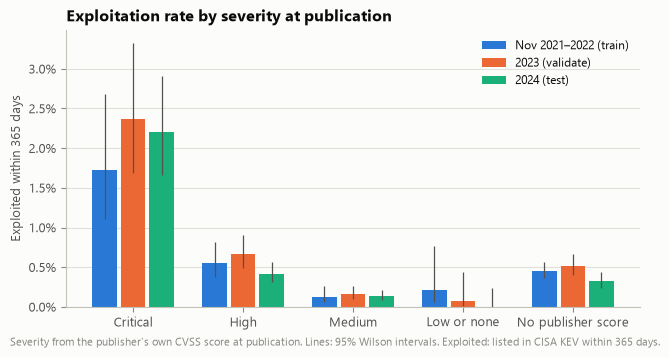

In [18]:
period_rate_chart(q1_severity, "Exploitation rate by severity at publication", "q1_severity",
                  note="Severity from the publisher's own CVSS score at publication. Lines: 95% Wilson intervals. "
                       "Exploited: listed in CISA KEV within 365 days.")

**Reading the chart:** compare the heights within each band across the three colours. Where the
intervals overlap, the difference between periods is within chance.

### Step 10 · The components of the CVSS vector

**What we are doing:** rates by three parts of the publisher's CVSS vector: how the flaw is reached
(attack vector), the privileges an attacker needs, and whether a user must take part.

**Why:** the severity score compresses these parts into one number. Looking at them separately shows
which carry the signal; for example, flaws reachable over the network with no privileges may matter far
more than the score alone suggests. Only CVEs with a publisher CVSS 3.x or 4.0 vector are included,
because version 2 vectors use different components.

In [19]:
q1_components = pd.concat({
    component: rates_by_period(model[model[component].notna()], component)
    for component in ("attack_vector", "privileges", "user_interaction")
}, names=["component", "value"])
show(q1_components, ["cves", "exploited", "rate", "rate_low", "rate_high", "lift",
                     "rate_train", "rate_validate", "rate_test"])
save_table(q1_components, "q1_rate_by_cvss_component")

                                  cves exploited   rate rate_low rate_high  lift rate_train rate_validate rate_test
component        value                                                                                             
attack_vector    Adjacent        2,675         7  0.26%    0.13%     0.54%  0.6x      0.15%         0.23%     0.35%
                 Local          12,898        61  0.47%    0.37%     0.61%  1.1x      0.54%         0.61%     0.35%
                 Network        41,157       182  0.44%    0.38%     0.51%  1.0x      0.44%         0.49%     0.42%
                 Physical          580         0  0.00%    0.00%     0.66%  0.0x      0.00%         0.00%     0.00%
privileges       High            7,722        20  0.26%    0.17%     0.40%  0.6x      0.00%         0.24%     0.42%
                 Low            22,686        62  0.27%    0.21%     0.35%  0.6x      0.54%         0.29%     0.18%
                 No privileges  26,902       168  0.62%    0.54%     0.7

WindowsPath('results/q1_rate_by_cvss_component.csv')

**Reading the result:** within each component, compare the rates and lifts. Values backed by only a
few hundred CVEs (for example "Physical") have wide intervals and should not be over-read. Lift is
measured against the overall rate of these CVEs only, those with a parseable vector.

*In the run of Nov 10, 2026:* needing no privileges goes with a rate of 0.62% (lift 1.4), against
0.26–0.27% when low or high privileges are needed; needing no user interaction, 0.55% (1.3×) against
0.22% when a user must take part. The attack vector barely separates: network 0.44%, local 0.47% (many
exploited local flaws are privilege escalations, used after a first foothold), adjacent 0.26%, and
physical access 0 of 580.

### Step 11 · Weakness class

**What we are doing:** rates by the publisher's first weakness class (CWE), ranked by the number of
exploited CVEs, with "No publisher CWE" kept as its own group.

**Why:** a weakness class says *what kind* of flaw it is, such as memory corruption, injection or a
missing authentication check, and some kinds are far easier to turn into a working attack than others.
Ranking by the number exploited, rather than by rate, keeps tiny classes with one lucky hit out of the
top rows. A separate list ranks by rate among classes with at least 200 CVEs.

In [20]:
q1_weakness = rates_by_period(model, "weakness").sort_values(["exploited", "cves"], ascending=False)
save_table(q1_weakness, "q1_rate_by_weakness")
print(f"{len(q1_weakness):,} weakness groups; the {TOP_N} with the most exploited CVEs:\n")
show(q1_weakness, ["cves", "exploited", "rate", "rate_low", "rate_high", "lift", "share_of_exploited"], rows=TOP_N)

large = q1_weakness[q1_weakness["cves"] >= MIN_CVES].sort_values("rate", ascending=False)
print(f"\nhighest rates among the {len(large)} groups with at least {MIN_CVES} CVEs:\n")
show(large, ["cves", "exploited", "rate", "rate_low", "rate_high", "lift"], rows=8)

623 weakness groups; the 12 with the most exploited CVEs:

                                             cves exploited   rate rate_low rate_high  lift share_of_exploited
weakness                                                                                                      
No publisher CWE                           43,441       215  0.49%    0.43%     0.57%  1.1x             50.95%
CWE-78 OS command injection                 1,082        16  1.48%    0.91%     2.39%  3.4x              3.79%
CWE-416 Use after free                      1,167        13  1.11%    0.65%     1.90%  2.6x              3.08%
CWE-20 Improper input validation            1,770        11  0.62%    0.35%     1.11%  1.4x              2.61%
CWE-502 Deserialization of untrusted data     660        10  1.52%    0.83%     2.77%  3.5x              2.37%
CWE-94 Code injection                         546        10  1.83%    1.00%     3.34%  4.2x              2.37%
CWE-306 Missing authentication                336    

**Reading the result:** the first table shows where the exploited CVEs are; the second shows which
reasonably common classes are most likely to be exploited. A class can be high in the first list
simply because it is common (cross-site scripting is the usual example), so read the rate and the
lift beside the count.

*In the run of Nov 10, 2026:* half of the exploited CVEs (215 of 422) have no publisher CWE at all.
Among classes with at least 200 CVEs, the highest rates are missing authentication (CWE-306, 2.98%,
6.9×), code injection (CWE-94, 1.83%), deserialization of untrusted data (CWE-502, 1.52%) and OS
command injection (CWE-78, 1.48%): flaws that hand an attacker control directly. SQL injection is
common but rarely exploited (5 of 3,577 CVEs, 0.14%).

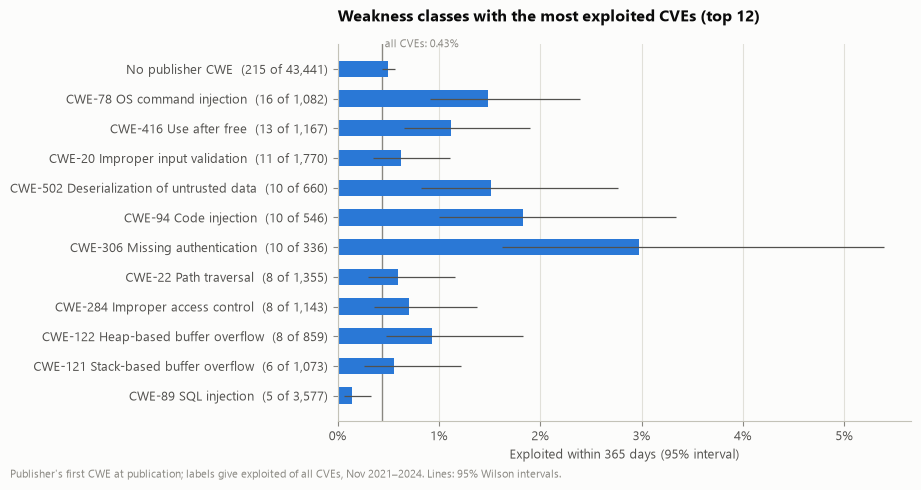

In [21]:
top_weak = q1_weakness.head(TOP_N)
ranked_rate_chart(top_weak, [f"{w}  ({e} of {c:,})" for w, e, c in zip(top_weak.index, top_weak["exploited"], top_weak["cves"])],
                  f"Weakness classes with the most exploited CVEs (top {TOP_N})", "q1_weakness",
                  note="Publisher's first CWE at publication; labels give exploited of all CVEs, Nov 2021–2024. "
                       "Lines: 95% Wilson intervals.", base=BASE_RATE)

**Reading the chart:** bars to the right of the hairline are classes exploited more often than the
average CVE. Long interval lines mean few CVEs; the labels give the counts behind each bar.

### Step 12 · Publishers, and how concentrated exploitation is

**What we are doing:** rates by publisher (the organisation that issued the CVE), and how concentrated
exploitation is among them.

**Why:** a few large vendors (operating systems, browsers, network devices) attract most attacks, while
many publishers issue CVEs that are rarely exploited. That matters twice over: it is a finding in its
own right, and it is the risk the proposal flagged, that a model could score well simply by learning
which publishers' CVEs get attacked. The concentration curve below sorts publishers by their
exploitation rate and plots the share of all CVEs against the share of exploited CVEs. Because it
uses the outcome to sort, it is an upper bound on what a publisher-only rule could achieve, not a
prediction.

In [22]:
q1_publisher = rates_by_period(model, "publisher").sort_values(["exploited", "cves"], ascending=False)
save_table(q1_publisher, "q1_rate_by_publisher")
with_exploits = int((q1_publisher["exploited"] > 0).sum())
print(f"{len(q1_publisher):,} publishers; {with_exploits} had at least one exploited CVE. "
      f"The {TOP_N} with the most exploited CVEs:\n")
show(q1_publisher, ["cves", "exploited", "rate", "rate_low", "rate_high", "lift", "share_of_cves",
                    "share_of_exploited"], rows=TOP_N)

def concentration_curve(t):
    "Publishers by descending rate: cumulative share of CVEs (x) and of exploited CVEs (y), from (0, 0)."
    s = t.sort_values(["rate", "exploited"], ascending=False)
    x = np.concatenate([[0.0], s["cves"].cumsum().to_numpy() / s["cves"].sum()])
    y = np.concatenate([[0.0], s["exploited"].cumsum().to_numpy() / s["exploited"].sum()])
    return x, y

curve_x, curve_y = concentration_curve(q1_publisher)
CONCENTRATION = {f"cves_for_{int(100 * level)}pct_of_exploited": float(curve_x[np.argmax(curve_y >= level)])
                 for level in (0.5, 0.8)}
for k in (5, 10):
    top = q1_publisher.head(k)
    CONCENTRATION[f"top{k}_share_of_exploited"] = float(top["share_of_exploited"].sum())
    CONCENTRATION[f"top{k}_share_of_cves"] = float(top["share_of_cves"].sum())
print("\n" + "\n".join(f"  {k}: {v:.1%}" for k, v in CONCENTRATION.items()))

340 publishers; 60 had at least one exploited CVE. The 12 with the most exploited CVEs:

                              cves exploited    rate rate_low rate_high   lift share_of_cves share_of_exploited
publisher                                                                                                      
Microsoft Corporation        3,148        86   2.73%    2.22%     3.36%   6.3x         3.24%             20.38%
MITRE                       20,891        60   0.29%    0.22%     0.37%   0.7x        21.51%             14.22%
Apple Inc.                   1,445        35   2.42%    1.75%     3.35%   5.6x         1.49%              8.29%
Chrome                         959        28   2.92%    2.03%     4.19%   6.7x         0.99%              6.64%
Cisco Systems, Inc.            961        15   1.56%    0.95%     2.56%   3.6x         0.99%              3.55%
Apache Software Foundation     778        12   1.54%    0.88%     2.68%   3.6x         0.80%              2.84%
Adobe Systems I

**Reading the result:** the top-publisher table gives each publisher's count, rate and lift. The lines
after it summarise the concentration: the share of all CVEs that holds half (and 80%) of the exploited
ones, when publishers are taken in order of their rate, and the share of exploited and of all CVEs
held by the five and ten publishers with the most exploited CVEs.

*In the run of Nov 10, 2026:* 7.6% of CVEs hold half of the exploited ones, and the five publishers
with the most exploited CVEs hold 53% of them while issuing 28% of all CVEs. Microsoft alone has 86
exploited CVEs (2.7%). MITRE, which issues CVEs for many small vendors, has 60, but at a rate below
the average because it issues so many.

A publisher here is a CNA, so one company can appear more than once: Google's Chrome team is its own
CNA ("Chrome": 28 exploited of 959), separate from Android and from Google's main CNA, and Cisco's
Talos team is separate from Cisco's product CNA. These figures need the publisher names from the NVD;
if Step 5 fell back to e-mail domains, the CNAs of one company are merged and the concentration
figures shift a little (for example, 6.3% of CVEs holding half instead of 7.6%).

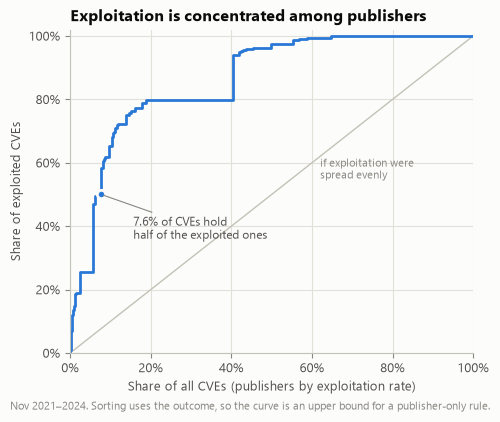

In [23]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot([0, 1], [0, 1], color=CONTEXT, linewidth=1, zorder=1)                    # no concentration
ax.step(curve_x, curve_y, where="post", color=ACCENT, linewidth=2, zorder=2)
x50 = CONCENTRATION["cves_for_50pct_of_exploited"]
ax.plot([x50], [0.5], "o", markersize=6, color=ACCENT, markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
ax.annotate(f"{x50:.1%} of CVEs hold\nhalf of the exploited ones", (x50, 0.5), xytext=(x50 + 0.08, 0.36),
            fontsize=8.5, color=INK_2, arrowprops={"arrowstyle": "-", "color": INK_3, "linewidth": 0.8})
ax.text(0.62, 0.55, "if exploitation were\nspread evenly", fontsize=8, color=INK_3, rotation=0)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(True)
ax.set_axisbelow(True)
ax.set_xlabel("Share of all CVEs (publishers by exploitation rate)")
ax.set_ylabel("Share of exploited CVEs")
ax.set_title("Exploitation is concentrated among publishers")
save_figure(fig, "q1_publisher_concentration",
            note="Nov 2021–2024. Sorting uses the outcome, so the curve is an upper bound for a publisher-only rule.")

**Reading the chart:** the further the blue curve rises above the grey diagonal, the more concentrated
exploitation is. A curve that climbs steeply at the left means a small share of CVEs, from a few
publishers, holds most of the exploited ones.

The next chart ranks the publishers with the most exploited CVEs by their rate.

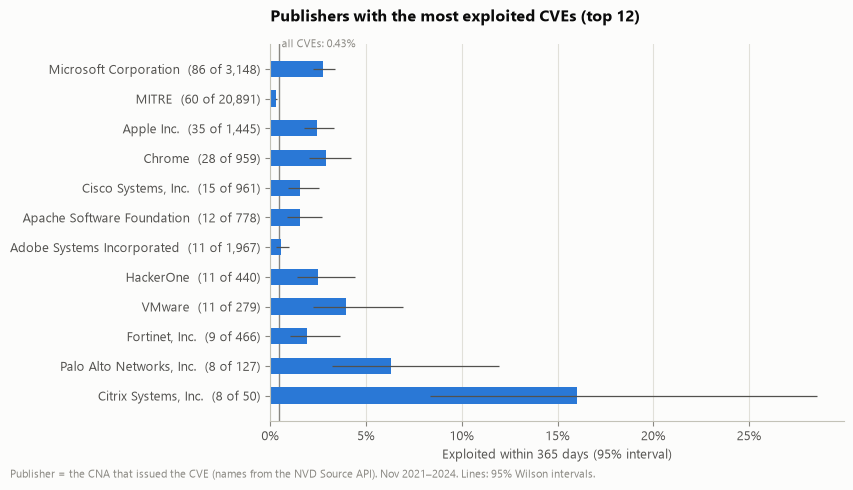

In [24]:
top_pub = q1_publisher.head(TOP_N)
ranked_rate_chart(top_pub, [f"{p}  ({e} of {c:,})" for p, e, c in zip(top_pub.index, top_pub["exploited"], top_pub["cves"])],
                  f"Publishers with the most exploited CVEs (top {TOP_N})", "q1_top_publishers",
                  note="Publisher = the CNA that issued the CVE (names from the NVD Source API). "
                       "Nov 2021–2024. Lines: 95% Wilson intervals.", base=BASE_RATE)

**Reading the chart:** each bar is one publisher's exploitation rate; the label gives its exploited
and total CVEs. Large publishers can hold many exploited CVEs at a modest rate, while some smaller
ones are exploited far more often relative to what they publish.

### Step 13 · Publishers the training data has never seen

**What we are doing:** for the validation and test periods, the share of CVEs, and of exploited CVEs,
that come from publishers with no CVE at all in the earlier periods.

**Why:** the number of publishers grows every year. A model that leans on the publisher can say
nothing useful about a publisher it has never seen, so this measures how much of each later period
falls outside what the earlier data covers. It is reported here because it shapes how `03_model.ipynb`
must handle unseen publishers (from the validation period only, under the rule on the test year).

In [25]:
def unseen_publishers(df, period, earlier):
    "Share of a period's CVEs and exploited CVEs whose publisher has no CVE in the earlier periods."
    seen = set(df.loc[df["period"].isin(earlier), "publisher"])
    part = df[df["period"] == period]
    new = ~part["publisher"].isin(seen)
    return {"period": period, "publishers": part["publisher"].nunique(),
            "new_publishers": part.loc[new, "publisher"].nunique(),
            "cves": len(part), "cves_from_new": int(new.sum()), "cves_from_new_share": float(new.mean()),
            "exploited": int(part[LABEL].sum()), "exploited_from_new": int((new & part[LABEL]).sum()),
            "exploited_from_new_share": float((new & part[LABEL]).sum() / max(part[LABEL].sum(), 1))}

q1_unseen = pd.DataFrame([unseen_publishers(model, "validate", ["train"]),
                          unseen_publishers(model, "test", ["train", "validate"])]).set_index("period")
show(q1_unseen)
save_table(q1_unseen, "q1_unseen_publishers")

         publishers new_publishers    cves cves_from_new cves_from_new_share exploited exploited_from_new exploited_from_new_share
period                                                                                                                            
validate        256             74  28,816           652               2.26%       145                  4                    2.76%
test            305             61  39,953         4,778              11.96%       149                 13                    8.72%


WindowsPath('results/q1_unseen_publishers.csv')

**Reading the result:** for each later period, how many of its publishers are new, and what share of
its CVEs and exploited CVEs they account for. A large share of CVEs from new publishers, but a small
share of exploited ones, would mean new publishers are rarely the ones attacked: the model can treat
"unseen publisher" as a group of its own without losing much.

*In the run of Nov 10, 2026:* in validation, 74 new publishers issued 2.3% of the CVEs and 4 of the
145 exploited ones (2.8%). In test, 61 new publishers issued 12% of the CVEs and 13 of the 149 exploited
ones (8.7%). Following the rule on test figures, the model design in `03_model.ipynb` relies on the
validation row; the test row is a description only. Either way, the model needs a sensible default
for a publisher it has not seen.

### Step 14 · What severity-based triage costs

**What we are doing:** measuring five simple triage rules in each period:

| Rule | Flags a CVE when |
|:--|:--|
| Patch everything | always |
| Publisher score 7.0+ | the publisher rated it High or Critical |
| Publisher score 9.0+ | the publisher rated it Critical |
| Score 7.0+, or no publisher score | as above, but unscored CVEs are treated as High |
| Published by Microsoft | Microsoft issued it (the simple publisher rule from the proposal's Table 1) |

For each rule: **effort** (the share of all CVEs it flags), **coverage** (the share of exploited CVEs
it catches, with an interval), **precision** (the share of flagged CVEs that were exploited) and
**lift** (precision divided by the base rate). Coverage is also given without the CVEs listed before
publication.

**Why:** these are the baselines the model must beat in Q2, and they answer the second half of Q1:
what does severity-based triage cost?

In [26]:
RULES = {
    "Patch everything":                   lambda d: pd.Series(True, index=d.index),
    "Publisher score 7.0+":               lambda d: d["cvss_score"].ge(7),
    "Publisher score 9.0+":               lambda d: d["cvss_score"].ge(9),
    "Score 7.0+, or no publisher score":  lambda d: d["cvss_score"].ge(7) | d["cvss_score"].isna(),
    "Published by Microsoft":             lambda d: d["cna"].eq("secure@microsoft.com"),
}

def evaluate_rule(d, flagged):
    "Effort, coverage (with a 95% interval), precision and lift of one rule on one set of CVEs."
    total, total_after = int(d[LABEL].sum()), int(d["label_after_pub"].sum())
    caught, n_flagged = int((flagged & d[LABEL]).sum()), int(flagged.sum())
    low, high = wilson_interval(caught, total)
    precision = caught / n_flagged if n_flagged else np.nan
    return {"flagged": n_flagged, "effort": n_flagged / len(d), "caught": caught, "coverage": caught / total,
            "coverage_low": float(low), "coverage_high": float(high), "precision": precision,
            "lift": precision / d[LABEL].mean(),
            "coverage_after_pub": int((flagged & d["label_after_pub"]).sum()) / total_after}

rows = []
for scope, d in [("all", model)] + [(p, model[model["period"] == p]) for p in PERIODS]:
    for rule, condition in RULES.items():
        rows.append({"period": scope, "rule": rule, **evaluate_rule(d, condition(d).fillna(False))})
q1_triage = pd.DataFrame(rows).set_index(["period", "rule"])
show(q1_triage.loc["all"], ["flagged", "effort", "caught", "coverage", "coverage_low", "coverage_high",
                            "precision", "lift", "coverage_after_pub"])
print("\ncoverage by period:")
print(q1_triage["coverage"].unstack("period")[PERIODS].map("{:.1%}".format).to_string())
save_table(q1_triage, "q1_triage_rules")

                                  flagged   effort caught coverage coverage_low coverage_high precision  lift coverage_after_pub
rule                                                                                                                            
Patch everything                   97,137  100.00%    422  100.00%       99.10%       100.00%     0.43%  1.0x            100.00%
Publisher score 7.0+               25,682   26.44%    208   49.29%       44.55%        54.04%     0.81%  1.9x             52.32%
Publisher score 9.0+                4,624    4.76%     99   23.46%       19.67%        27.73%     2.14%  4.9x             25.89%
Score 7.0+, or no publisher score  65,506   67.44%    380   90.05%       86.82%        92.55%     0.58%  1.3x             89.37%
Published by Microsoft              3,148    3.24%     86   20.38%       16.81%        24.48%     2.73%  6.3x             21.25%

coverage by period:
period                              train validate    test
rule             

WindowsPath('results/q1_triage_rules.csv')

**Reading the result:** the first table covers the whole modelling period; the second shows how
coverage changes from period to period. A good rule has high coverage for little effort; precision and
lift say how much better than random each flagged CVE is. Compare "Publisher score 7.0+" with "Score
7.0+, or no publisher score" to see what the unscored CVEs add, at what extra effort.

*In the run of Nov 10, 2026, all periods together:*

| Rule | Effort (CVEs flagged) | Coverage (exploited caught) | Precision |
|---|---|---|---|
| Publisher score 7.0+ | 26% | 49% | 0.81% |
| Publisher score 9.0+ | 4.8% | 23% | 2.1% |
| Score 7.0+, or no publisher score | 67% | 90% | 0.58% |
| Published by Microsoft | 3.2% | 20% | 2.7% |

Adding the unscored CVEs raises coverage from 49% to 90%, but at the cost of flagging two-thirds of all
CVEs. Coverage of the 7.0+ rule rises from 35% in training to 49% in validation and 62% in test, mostly
because publishers score more of their own CVEs. This is the bar the model has to beat: more coverage
for the same effort.

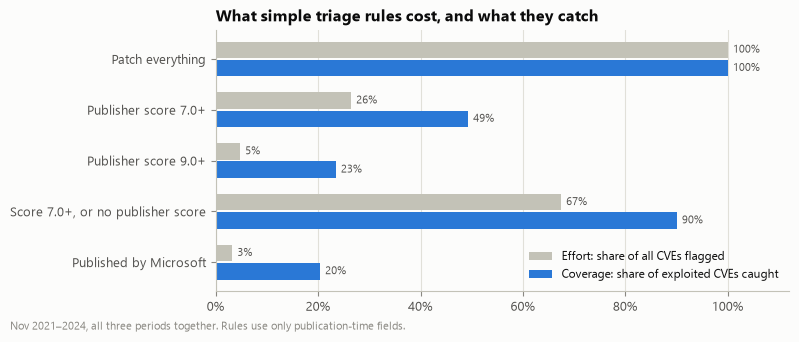

In [27]:
whole = q1_triage.loc["all"].iloc[::-1]
y, height = np.arange(len(whole)), 0.36
fig, ax = plt.subplots(figsize=(7.4, 3.4))
ax.barh(y + height / 2, whole["effort"], height=height * 0.9, color=CONTEXT, label="Effort: share of all CVEs flagged", zorder=2)
ax.barh(y - height / 2, whole["coverage"], height=height * 0.9, color=ACCENT, label="Coverage: share of exploited CVEs caught", zorder=2)
for yi, (effort, coverage) in zip(y, zip(whole["effort"], whole["coverage"])):
    ax.text(effort + 0.01, yi + height / 2, f"{effort:.0%}", va="center", fontsize=8, color=INK_2)
    ax.text(coverage + 0.01, yi - height / 2, f"{coverage:.0%}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, whole.index)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, 1.12)
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_title("What simple triage rules cost, and what they catch")
ax.legend(loc="lower right", fontsize=8.5)
save_figure(fig, "q1_triage", note="Nov 2021–2024, all three periods together. Rules use only publication-time fields.")

**Reading the chart:** for each rule, the grey bar is the work it asks for and the blue bar is what it
catches. A useful rule has a blue bar much longer than its grey bar. "Patch everything" is the
reference: 100% of the effort for 100% of the coverage.

---

## Stage D · Q3: How soon after publication are CVEs listed as exploited?

### Step 15 · The delay from publication to listing, by year

**What we are doing:** for the exploited CVEs of each publication year, summarising the delay between
publication and KEV listing (`days_to_kev`, in calendar days):

- the share listed **on or before** the publication day (0 days or fewer), and the share listed
  *before* it;
- the share listed within 7, 30 and 90 days;
- the median delay with a bootstrap 95% interval, the quartiles, and the median among CVEs listed
  *after* their publication day.

**Why:** the time between disclosure and confirmed exploitation is the time a defender has to act.
The validation sample (early 2023) found 13 of 51 listed on or before publication and a median of 20
days; this measures the same for every year. Only CVEs exploited within 365 days are included, so
every year is observed over the same full window. Later listings are discussed in Step 17.

In [28]:
def timing_summary(days):
    "Delay statistics (calendar days) for one group of exploited CVEs."
    d = np.asarray(days, dtype=float)
    low, high = bootstrap_ci(d)
    on_before = int((d <= 0).sum())
    share_low, share_high = wilson_interval(on_before, d.size)
    after = d[d > 0]
    return {"exploited": d.size, "listed_before_pub_day": int((d < 0).sum()),
            "listed_on_pub_day": int((d == 0).sum()), "on_or_before_share": on_before / d.size,
            "on_or_before_low": float(share_low), "on_or_before_high": float(share_high),
            "within_7_days_share": float((d <= 7).mean()), "within_30_days_share": float((d <= 30).mean()),
            "within_90_days_share": float((d <= 90).mean()),
            "median_days": float(np.median(d)), "median_low": low, "median_high": high,
            "q1_days": float(np.percentile(d, 25)), "q3_days": float(np.percentile(d, 75)),
            "median_days_after_pub_day": float(np.median(after)) if after.size else np.nan}

exploited_cves = model[model[LABEL]].copy()
exploited_cves["days"] = exploited_cves["days_to_kev"].astype(float)
groups = ([(str(c), exploited_cves[exploited_cves["cohort"] == c]) for c in COHORTS]
          + [("all", exploited_cves)])
q3_timing = pd.DataFrame.from_dict({name: timing_summary(g["days"]) for name, g in groups}, orient="index")
q3_timing.index.name = "publication year"
show(q3_timing, ["exploited", "listed_before_pub_day", "listed_on_pub_day", "on_or_before_share",
                 "within_7_days_share", "within_30_days_share", "median_days", "median_low", "median_high",
                 "median_days_after_pub_day"])
save_table(q3_timing, "q3_timing_by_year")
check("D1-timing-complete", int(q3_timing.loc["all", "exploited"]) == int(model[LABEL].sum())
      and not exploited_cves["days"].isna().any(), exploited=int(q3_timing.loc["all", "exploited"]))

                 exploited listed_before_pub_day listed_on_pub_day on_or_before_share within_7_days_share within_30_days_share  median_days  median_low  median_high  median_days_after_pub_day
publication year                                                                                                                                                                               
2021 (Nov–Dec)          16                     3                 2             31.25%              50.00%               50.00%         20.0         0.0        140.0                      113.0
2022                   112                    32                 7             34.82%              45.54%               60.71%         14.0         3.5         25.0                       46.0
2023                   145                    13                33             31.72%              60.00%               73.79%          4.0         2.0          7.0                       12.0
2024                   149              

**Reading the result:** one row per publication year, and one for all years together. The
2021 (Nov–Dec) row covers only two months and few CVEs, so its figures are the least certain. Read
`on_or_before_share` as "already exploited when the record appeared", and `median_days` as the typical
wait among the rest. The last column drops the CVEs listed on or before their publication day, giving
the typical delay when there *was* a delay.

*In the run of Nov 10, 2026:*

| Year | Exploited | On or before publication | Median days (95% interval) |
|---|---|---|---|
| 2021 (Nov–Dec) | 16 | 31% | 20 (0–140) |
| 2022 | 112 | 34.8% | 14 (3.5–25) |
| 2023 | 145 | 31.7% | 4 (2–7) |
| 2024 | 149 | 26.8% | 7 (3–19) |
| All | 422 | 30.8% | 6 (4–9) |

About one exploited CVE in three is already in KEV when its record is published, and half are listed
within about a week.

### Step 16 · Has the delay changed?

**What we are doing:** comparing 2023 and 2024 with 2022 (the first full year of KEV): the change in
the median delay and in the share listed on or before the publication day, each with a bootstrap 95%
interval.

**Why:** a single median per year can move by chance, especially with about 130 to 150 cases per year.
The interval for the *difference* says whether a change is larger than chance alone would produce:
if it includes zero, the data cannot tell a change from noise.

In [29]:
def compare_years(base_year, other_year):
    "Change from base_year to other_year in the median delay and the on-or-before share."
    a = exploited_cves.loc[exploited_cves["cohort"] == base_year, "days"].to_numpy()
    b = exploited_cves.loc[exploited_cves["cohort"] == other_year, "days"].to_numpy()
    rows = []
    for measure, values_a, values_b, stat in [("median delay (days)", a, b, np.median),
                                              ("share on or before publication day", a <= 0, b <= 0, np.mean)]:
        estimate, low, high = bootstrap_difference(values_a, values_b, stat=stat)
        rows.append({"comparison": f"{other_year} vs {base_year}", "measure": measure,
                     f"value_{base_year}": float(stat(values_a)), "value_other": float(stat(values_b)),
                     "change": estimate, "change_low": low, "change_high": high,
                     "clear_change": bool(low > 0 or high < 0)})
    return rows

q3_change = pd.DataFrame(compare_years("2022", "2023") + compare_years("2022", "2024")).set_index(["comparison", "measure"])
print(q3_change.to_string(float_format=lambda v: f"{v:,.3f}"))
save_table(q3_change, "q3_change_vs_2022")

                                                 value_2022  value_other  change  change_low  change_high  clear_change
comparison   measure                                                                                                   
2023 vs 2022 median delay (days)                     14.000        4.000 -10.000     -22.000        0.500         False
             share on or before publication day       0.348        0.317  -0.031      -0.151        0.080         False
2024 vs 2022 median delay (days)                     14.000        7.000  -7.000     -20.000        9.000         False
             share on or before publication day       0.348        0.268  -0.080      -0.198        0.034         False


WindowsPath('results/q3_change_vs_2022.csv')

**Reading the result:** for each comparison and measure, the value in each year, the change, and its
95% interval. `clear_change` is `True` only when the interval excludes zero. Shares are fractions
here (0.10 means 10 percentage points), and medians are in days.

*In the run of Nov 10, 2026:* compared with 2022, the median delay was 10 days shorter in 2023 (95%
interval −22 to +0.5) and 7 days shorter in 2024 (−20 to +9). Both intervals include zero, and so do
the intervals for the on-or-before share. The data show no clear change in how quickly exploited CVEs
are listed.

The chart below shows the whole distribution, not just the median: for each year, the share of its
exploited CVEs that had been listed by each day after publication.

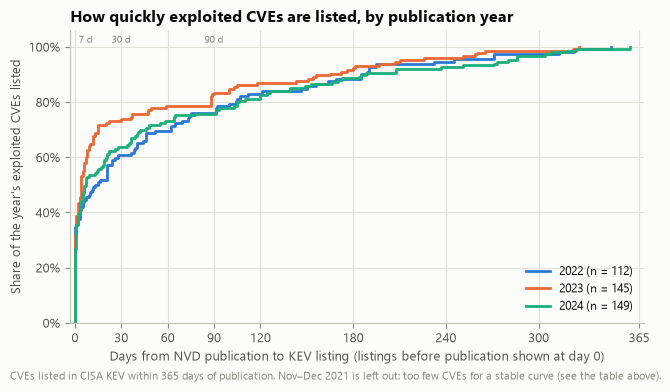

In [30]:
fig, ax = plt.subplots(figsize=(7.4, 3.8))
for year in ["2022", "2023", "2024"]:
    d = np.sort(np.clip(exploited_cves.loc[exploited_cves["cohort"] == year, "days"].to_numpy(), 0, None))
    share = np.arange(1, d.size + 1) / d.size
    ax.step(np.concatenate([[0], d]), np.concatenate([[0], share]), where="post",
            color=COHORT_COLORS[year], linewidth=2, label=f"{year} (n = {d.size})")
for day in (7, 30, 90):
    ax.text(day, 1.015, f"{day} d", ha="center", fontsize=7.5, color=INK_3)
ax.set_xlim(-3, 368)
ax.set_ylim(0, 1.06)
ax.set_xticks([0, 30, 60, 90, 120, 180, 240, 300, 365])
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(True)
ax.set_axisbelow(True)
ax.set_xlabel("Days from NVD publication to KEV listing (listings before publication shown at day 0)")
ax.set_ylabel("Share of the year's exploited CVEs listed")
ax.set_title("How quickly exploited CVEs are listed, by publication year")
ax.legend(loc="lower right", fontsize=8.5)
save_figure(fig, "q3_time_to_listing", note="CVEs listed in CISA KEV within 365 days of publication. "
            "Nov–Dec 2021 is left out: too few CVEs for a stable curve (see the table above).")

**Reading the chart:** where a line starts on the left edge is the share already listed on or before
the publication day; the steeper the early rise, the faster listing follows publication. Lines that
lie close together mean the timing has not changed much between years.

The next chart compares the median delay of each year directly, with its interval.

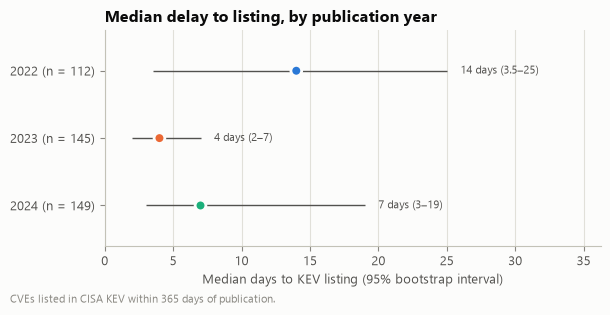

In [31]:
years = ["2022", "2023", "2024"]
med = q3_timing.loc[years]
fig, ax = plt.subplots(figsize=(6.4, 2.8))
y = np.arange(len(years))[::-1]
ax.errorbar(med["median_days"], y, xerr=[med["median_days"] - med["median_low"], med["median_high"] - med["median_days"]],
            fmt="none", ecolor=INK_2, elinewidth=1, zorder=2)
ax.scatter(med["median_days"], y, s=60, color=[COHORT_COLORS[v] for v in years], edgecolor=SURFACE, linewidth=2, zorder=3)
for yi, (m, lo, hi) in zip(y, med[["median_days", "median_low", "median_high"]].to_numpy()):
    # :g keeps a half day (a median of an even count can be 3.5) instead of rounding it away
    m, lo, hi = (round(float(v), 1) for v in (m, lo, hi))
    ax.text(hi + 1, yi, f"{m:g} days ({lo:g}–{hi:g})", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, [f"{v} (n = {int(n)})" for v, n in zip(years, med["exploited"])])
ax.set_ylim(-0.6, len(years) - 0.4)
ax.set_xlim(left=0, right=max(med["median_high"].max() * 1.45, 10))
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_xlabel("Median days to KEV listing (95% bootstrap interval)")
ax.set_title("Median delay to listing, by publication year")
save_figure(fig, "q3_median_delay", note="CVEs listed in CISA KEV within 365 days of publication.")

**Reading the chart:** each dot is a year's median delay; the line is its 95% interval. Overlapping
lines mean the medians are not clearly different.

### Step 17 · Late listings (after day 365): context only

**What we are doing:** counting, for each publication year, CVEs that KEV listed more than 365 days
after publication, and how long each year has been observed.

**Why:** these late listings are not counted as exploited in the label (they fall outside the window),
but a reader may ask how many there are. The years are **not** comparable here: the KEV snapshot was
taken in November 2026, so CVEs from 2022 have had almost four years in which a late listing could
occur, and those from late 2024 less than two.

In [32]:
def kev_snapshot_date():
    "The release date of the KEV snapshot used in 01_acquire_data.ipynb (from its log), else the latest listing."
    try:
        released = json.loads((LOGS / "acquisition_log.json").read_text(encoding="utf-8"))["sources"]["CISA KEV catalog"]["date_released"]
        return pd.Timestamp(released[:10])
    except (FileNotFoundError, KeyError, TypeError, json.JSONDecodeError):
        return model["kev_date_added"].max()

SNAPSHOT = kev_snapshot_date()
late = model.assign(late=model["in_kev"] & model["days_to_kev"].gt(LABEL_DAYS).fillna(False))
q3_late = late.groupby("cohort", observed=True).agg(cves=("cve_id", "size"), ever_listed=("in_kev", "sum"),
                                                     within_365=(LABEL, "sum"), after_365=("late", "sum"))
q3_late["years_observed_for_latest_cve"] = [round((SNAPSHOT - pd.Timestamp(f"{str(c)[:4]}-12-31")).days / 365.25, 1) for c in q3_late.index]
print(f"KEV snapshot: {SNAPSHOT:%Y-%m-%d}\n")
show(q3_late)
save_table(q3_late, "q3_late_listings")

KEV snapshot: 2026-11-10

                  cves ever_listed within_365 after_365  years_observed_for_latest_cve
cohort                                                                                
2021 (Nov–Dec)   3,295          26         16        10                            4.9
2022            25,073         131        112        19                            3.9
2023            28,816         166        145        21                            2.9
2024            39,953         161        149        12                            1.9


WindowsPath('results/q3_late_listings.csv')

**Reading the result:** for each year, the CVEs ever listed, those listed within the 365-day window,
and those listed later. The last column shows how long the latest CVE of each year has been observed:
the shorter it is, the fewer late listings that year has had time to collect, so the late counts
should not be compared across years.

---

## Stage E · Summary

### Step 18 · Key findings, checks and files

**What we are doing:** collecting the headline numbers from the tables above into a short list,
listing every check and every file written, and saving them as `results/descriptive_summary.json`
and `logs/descriptive_log.json`.

**Why:** the report and the slides need the same numbers as the notebook, so they are taken from the
computed tables rather than copied by hand. Every number below can be traced to a table in `results/`.

In [33]:
sev = q1_severity
triage = q1_triage.loc["all"]
YEARS = ["2022", "2023", "2024"]                              # the full publication years

def days(value, sign=False):
    "A number of days to one decimal, without a trailing .0 (a median can fall on a half day)."
    v = round(float(value), 1)
    return f"{v:+g}" if sign else f"{v:g}"

FINDINGS = {
    "base rate": f"{BASE_RATE:.2%} of CVEs published Nov 2021–2024 were listed in KEV within 365 days "
                 f"({int(model[LABEL].sum())} of {len(model):,}); by period: "
                 + ", ".join(f"{PERIOD_NAMES[p]} {rates_period.loc[p, 'rate']:.2%}" for p in PERIODS),
    "no publisher score": f"CVEs without a publisher score are {sev.loc['No publisher score', 'share_of_cves']:.0%} of all CVEs "
                          f"and {sev.loc['No publisher score', 'share_of_exploited']:.0%} of exploited ones",
    "critical vs medium": f"Critical: {sev.loc['Critical', 'rate']:.2%} exploited; High: {sev.loc['High', 'rate']:.2%}; "
                          f"Medium: {sev.loc['Medium', 'rate']:.2%}",
    "high-or-critical rule": f"'Publisher score 7.0+' flags {triage.loc['Publisher score 7.0+', 'effort']:.0%} of CVEs "
                             f"and catches {triage.loc['Publisher score 7.0+', 'coverage']:.0%} of exploited ones "
                             f"(precision {triage.loc['Publisher score 7.0+', 'precision']:.2%})",
    "publisher concentration": f"taking publishers by exploitation rate, {CONCENTRATION['cves_for_50pct_of_exploited']:.1%} "
                               f"of CVEs hold half of the exploited ones; the 5 publishers with the most exploited CVEs "
                               f"hold {CONCENTRATION['top5_share_of_exploited']:.0%} of them and "
                               f"{CONCENTRATION['top5_share_of_cves']:.0%} of all CVEs",
    "unseen publishers (validation)": f"{q1_unseen.loc['validate', 'cves_from_new_share']:.0%} of 2023 CVEs and "
                                      f"{q1_unseen.loc['validate', 'exploited_from_new_share']:.0%} of exploited ones "
                                      f"come from publishers absent from the training period",
    "listed on or before publication": "; ".join(f"{y}: {q3_timing.loc[y, 'on_or_before_share']:.0%}" for y in YEARS),
    "median delay": "; ".join(f"{y}: {days(q3_timing.loc[y, 'median_days'])} days ({days(q3_timing.loc[y, 'median_low'])}"
                              f"–{days(q3_timing.loc[y, 'median_high'])})" for y in YEARS),
    "change since 2022": "; ".join(f"{y}: {days(c['change'], sign=True)} days ({days(c['change_low'], sign=True)} to "
                                   f"{days(c['change_high'], sign=True)}), "
                                   + ("a clear change" if c["clear_change"] else "not distinguishable from chance")
                                   for y, c in ((y, q3_change.loc[(f"{y} vs 2022", "median delay (days)")]) for y in YEARS[1:])),
}
for topic, text in FINDINGS.items():
    print(f"- {topic}: {text}")
(RESULTS / "descriptive_summary.json").write_text(json.dumps(FINDINGS, indent=2), encoding="utf-8")
RUN["files"].append(str(RESULTS / "descriptive_summary.json"))

- base rate: 0.43% of CVEs published Nov 2021–2024 were listed in KEV within 365 days (422 of 97,137); by period: Nov 2021–2022 0.45%, 2023 0.50%, 2024 0.37%
- no publisher score: CVEs without a publisher score are 41% of all CVEs and 41% of exploited ones
- critical vs medium: Critical: 2.14% exploited; High: 0.52%; Medium: 0.14%
- high-or-critical rule: 'Publisher score 7.0+' flags 26% of CVEs and catches 49% of exploited ones (precision 0.81%)
- publisher concentration: taking publishers by exploitation rate, 7.6% of CVEs hold half of the exploited ones; the 5 publishers with the most exploited CVEs hold 53% of them and 28% of all CVEs
- unseen publishers (validation): 2% of 2023 CVEs and 3% of exploited ones come from publishers absent from the training period
- listed on or before publication: 2022: 35%; 2023: 32%; 2024: 27%
- median delay: 2022: 14 days (3.5–25); 2023: 4 days (2–7); 2024: 7 days (3–19)
- change since 2022: 2023: -10 days (-22 to +0.5), not distinguishable from ch

**Reading the result:** one line per headline finding, with its numbers. These lines feed the
report's results section.

**The checks and files:** the last cell lists every check and every file this run wrote, and saves
the run log.

In [34]:
EXPECTED_CHECKS = ["A1-statistics-selftest", "B1-table-loaded", "B2-publisher-names", "B3-cvss-parser-selftest",
                   "B4-derived-columns", "C0-rate-table-selftest", "D1-timing-complete"]
for name in EXPECTED_CHECKS:
    RUN["checks"].setdefault(name, {"verdict": "FAIL", "error": "check never ran"})
RUN["finished"] = now_iso()
(LOGS / "descriptive_log.json").write_text(json.dumps(RUN, indent=2, default=str), encoding="utf-8")

verdicts = [c["verdict"] for c in RUN["checks"].values()]
print(f"{verdicts.count('PASS')}/{len(verdicts)} checks passed, {verdicts.count('WARN')} to review, "
      f"{verdicts.count('FAIL')} failed")
for name, c in RUN["checks"].items():
    print(f"  {c['verdict']:<5} {name}")
print(f"\n{len(RUN['files'])} files written:")
for path in RUN["files"]:
    print(f"  {path}")

7/7 checks passed, 0 to review, 0 failed
  PASS  A1-statistics-selftest
  PASS  B1-table-loaded
  PASS  B2-publisher-names
  PASS  B3-cvss-parser-selftest
  PASS  B4-derived-columns
  PASS  C0-rate-table-selftest
  PASS  D1-timing-complete

18 files written:
  results\q1_rate_by_period_and_year.csv
  results\q1_rate_by_severity.csv
  figures\q1_severity.png
  results\q1_rate_by_cvss_component.csv
  results\q1_rate_by_weakness.csv
  figures\q1_weakness.png
  results\q1_rate_by_publisher.csv
  figures\q1_publisher_concentration.png
  figures\q1_top_publishers.png
  results\q1_unseen_publishers.csv
  results\q1_triage_rules.csv
  figures\q1_triage.png
  results\q3_timing_by_year.csv
  results\q3_change_vs_2022.csv
  figures\q3_time_to_listing.png
  figures\q3_median_delay.png
  results\q3_late_listings.csv
  results\descriptive_summary.json


**Reading the result:** the target is 7 of 7 checks passed (`B2` may be `WARN` if the NVD could not be
reached for publishers' names), and a list of the tables and figures written.

## What comes next

`03_model.ipynb` answers Q2: a ranking model trained on the training period, tuned on 2023 and tested
once on 2024. It starts from the baselines in Step 14, the CVSS components in Step 10, the weakness
classes in Step 11, and the handling of unseen publishers that Step 13 calls for. Following the rule
at the top of this notebook, its design uses only the training and validation columns of these tables.